In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import glob

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


In [3]:
files = glob.glob(
    "/kaggle/input/**/household_power_consumption.txt",
    recursive=True
)

if not files:
    raise FileNotFoundError(
        "Please add the Household Electric Power Consumption dataset "
        "to your Kaggle Notebook."
    )

file_path = files[0]

print("Dataset Path:", file_path)

df = pd.read_csv(
    file_path,
    sep=";",
    na_values="?",
    low_memory=False
)

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Path: /kaggle/input/datasets/uciml/electric-power-consumption-data-set/household_power_consumption.txt
Dataset Shape: (2075259, 9)
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8           

In [4]:
features = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

df[features] = df[features].apply(
    pd.to_numeric, errors="coerce"
)

df = df.sort_values("Datetime").reset_index(drop=True)

print("Missing Values Before Selection:")
print(df[features].isnull().sum())

# Find consecutive, valid minute-level records
valid = df["Datetime"].notna() & df[features].notna().all(axis=1)

one_minute = df["Datetime"].diff().eq(
    pd.Timedelta(minutes=1)
)

continuous = valid & valid.shift(fill_value=False) & one_minute

group_id = (~continuous).cumsum()

group_sizes = valid.groupby(group_id).sum()

eligible = group_sizes[group_sizes >= 10000]

if eligible.empty:
    raise ValueError(
        "No block of 10,000 consecutive valid minutes found."
    )

selected_group = eligible.index[0]

df = df.loc[
    (group_id == selected_group) & valid
].iloc[:10000].copy()

df = df.reset_index(drop=True)

print("\nSelected Dataset Shape:", df.shape)
print("Missing Values After Selection:", df[features].isnull().sum().sum())
print("Start:", df["Datetime"].iloc[0])
print("End:", df["Datetime"].iloc[-1])

Missing Values Before Selection:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Selected Dataset Shape: (10000, 10)
Missing Values After Selection: 0
Start: 2006-12-21 11:25:00
End: 2006-12-28 10:04:00


In [5]:
data = df[features].values.astype("float32")

train_size = int(len(data) * 0.8)

scaler = MinMaxScaler()

scaler.fit(data[:train_size])

scaled_data = scaler.transform(data)

print("Normalized Data Shape:", scaled_data.shape)
print(scaled_data[:5])

Normalized Data Shape: (10000, 7)
[[0.00611477 0.         0.59097195 0.00552486 0.         0.
  0.        ]
 [0.00611477 0.         0.59511757 0.00552486 0.         0.
  0.        ]
 [0.00587959 0.         0.5550442  0.00552486 0.         0.
  0.        ]
 [0.00587959 0.         0.57392883 0.00552486 0.         0.
  0.        ]
 [0.00587959 0.         0.57208633 0.00552486 0.         0.
  0.        ]]


In [6]:
LOOKBACK = 60

def create_sequences(data, steps):
    X, y = [], []

    for i in range(steps, len(data)):
        X.append(data[i-steps:i])
        y.append(data[i, 0])

    return np.array(X), np.array(y)

X, y = create_sequences(scaled_data, LOOKBACK)

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (9940, 60, 7)
Output Shape: (9940,)


In [7]:
split_index = train_size - LOOKBACK

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (7940, 60, 7)
X_test: (2000, 60, 7)
y_train: (7940,)
y_test: (2000,)


In [8]:
model = Sequential([
    Input(shape=(LOOKBACK, 7)),
    LSTM(64, activation="tanh", return_sequences=False),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

model.summary()

2026-10-16 07:01:25.625024: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,545 (80.25 KB)

 Trainable params: 20,545 (80.25 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

Epoch 1/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - loss: 0.0134 - mae: 0.0835 - val_loss: 0.0032 - val_mae: 0.0395
Epoch 2/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0076 - mae: 0.0614 - val_loss: 0.0026 - val_mae: 0.0331
Epoch 3/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0066 - mae: 0.0562 - val_loss: 0.0022 - val_mae: 0.0298
Epoch 4/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0063 - mae: 0.0538 - val_loss: 0.0021 - val_mae: 0.0296
Epoch 5/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0060 - mae: 0.0522 - val_loss: 0.0019 - val_mae: 0.0277
Epoch 6/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0059 - mae: 0.0519 - val_loss: 0.0018 - val_mae: 0.0274
Epoch 7/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 0.0056 - mae: 0.0496 - val_loss: 0.0016 - val_mae: 0.0252
Epoch 8/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.0055 - mae: 0.0485 - val_loss: 0.0016 - val_mae: 0.0245
Epoch 9/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/

In [10]:
predicted_scaled = model.predict(X_test).flatten()

# Convert normalized values to original scale
power_min = scaler.data_min_[0]
power_range = scaler.data_range_[0]

actual = y_test * power_range + power_min
predicted = predicted_scaled * power_range + power_min

print("Prediction Completed!")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
Prediction Completed!


In [11]:
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
r2 = r2_score(actual, predicted)

print("MODEL EVALUATION")
print(f"MAE: {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")
print(f"R² Score: {r2:.4f}")
print(f"R² Explained Variance: {r2 * 100:.2f}%")

MODEL EVALUATION
MAE: 0.1123 kW
RMSE: 0.2493 kW
R² Score: 0.9188
R² Explained Variance: 91.88%


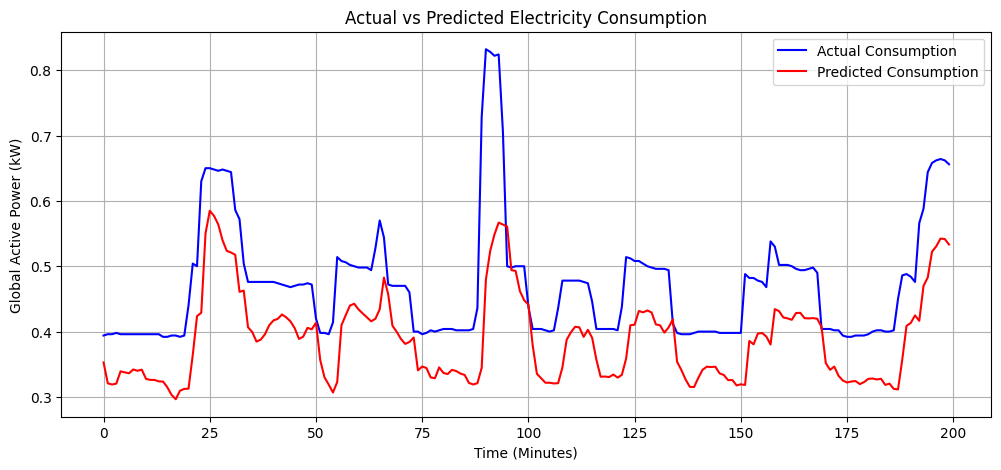

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    actual[:200],
    label="Actual Consumption",
    color="blue"
)

plt.plot(
    predicted[:200],
    label="Predicted Consumption",
    color="red"
)

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Time (Minutes)")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
results = pd.DataFrame({
    "Actual (kW)": actual[:10],
    "Predicted (kW)": predicted[:10]
})

results["Absolute Error"] = abs(
    results["Actual (kW)"] - results["Predicted (kW)"]
)

print("Predictions on Unseen Records")
print(results.round(4))

Predictions on Unseen Records
   Actual (kW)  Predicted (kW)  Absolute Error
0        0.394          0.3528          0.0412
1        0.396          0.3208          0.0752
2        0.396          0.3191          0.0769
3        0.398          0.3204          0.0776
4        0.396          0.3392          0.0568
5        0.396          0.3376          0.0584
6        0.396          0.3363          0.0597
7        0.396          0.3421          0.0539
8        0.396          0.3400          0.0560
9        0.396          0.3418          0.0542


In [14]:
last_sequence = scaled_data[-LOOKBACK:]

last_sequence = last_sequence.reshape(
    1, LOOKBACK, len(features)
)

next_scaled = model.predict(
    last_sequence,
    verbose=0
)[0, 0]

next_power = next_scaled * power_range + power_min

print(f"Next Minute Predicted Consumption: {next_power:.4f} kW")

Next Minute Predicted Consumption: 0.3046 kW
